# Woody P3 peaks and the N2-to-P3 peak-to-peak amplitude

`preproc_pipe/extract_EEG_trial_features.py` scores every mountain trial with Woody alignment: each trial is slid against the subject's P3 template within ±100 ms, and the amplitude is read at the template's peak, shifted by the best lag. The P3 search window is now **0.25–0.80 s** (was 0.60–0.95 s), so it also covers the N2. The N2-to-P3 peak-to-peak amplitude (`<ch>_N2P3_ptp_woody`) is the Woody P3 peak minus the trial's minimum between 0.25 s and the P3 peak, so it is never negative.

This notebook recomputes the fit for one subject and channel, checks it against the saved feature table, and plots:
1. the template and the clean-trial average,
2. the mnt-correct trials that had a **negative** amplitude with the old 0.60–0.95 s window, re-scored with the new window,
3. the trials with the smallest peak-to-peak amplitude,
4. typical trials,
5. the old amplitude against the new peak-to-peak value, and counts for the subjects with a DM.

Each figure is also saved as a PNG in this folder (`SAVE_DIR`).

Trial panels: black = 10 Hz low-passed trial (what Woody uses), grey = unfiltered epoch, blue dashed = template shifted by the trial's lag, red dot = Woody P3 peak, purple dot = N2 trough, orange band = P3 window, light band = window ± max lag (search range).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
mne.set_log_level('ERROR')
sys.path.insert(0, os.path.join(os.path.abspath('..'), 'preproc_pipe'))
import extract_EEG_trial_features as F

SUBJECT = 'sub-723'
CH = 'cz'
COMP = 'P3'
TRIAL_FILTER = 'mnt-correct'   # 'mnt-correct' (trials in the DM) or 'mnt' (all mountain trials)
N_EXAMPLES = 12
SAVE_DIR = '.'                 # PNGs are saved here
DM_SUBJECTS = ['sub-670', 'sub-695', 'sub-721', 'sub-723', 'sub-726', 'sub-730']  # subjects with a DM
# feature tables from before the window change (P3 window 0.60-0.95 s)
OLD_FEAT_DIR = '/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/backup_preproc_before_overwrite_2026-11-05'
comp = F.COMPONENTS[COMP]
print(f"{COMP} window: {comp['win']} s, Woody max lag {F.WOODY_MAX_LAG * 1e3:.0f} ms")

def savefig(fig, name):
    path = os.path.join(SAVE_DIR, f'vis_p3_peak_{SUBJECT}_{CH}_{name}.png')
    fig.savefig(path, dpi=130)
    print(f'saved {path}')

def load_old_features(subject):
    return pd.read_csv(os.path.join(OLD_FEAT_DIR, subject, 'features', f'{subject}_EEG_trial_features.csv.gz'))

P3 window: (0.25, 0.8) s, Woody max lag 100 ms


## Recompute the Woody fit
Same steps as `extract_subject`: stimulus-locked epochs of the mountain trials (−0.2 to 1.6 s, baseline −0.2–0 s, linear detrend) from the preprocessed `.fif`, pooled over runs, 10 Hz low-pass, template iterated on the clean trials (peak-to-peak ≤ 100 µV on the channel).

In [2]:
def woody_for_subject(subject, ch):
    eeg = F.load_eeg_runs(subject)
    rows, X_list, ok_list = [], [], []
    for run_key in F.RUN_KEYS:
        if run_key not in eeg or ch not in eeg[run_key].ch_names:
            continue
        raw = eeg[run_key]
        run_id = int(run_key[-1])
        sfreq = raw.info['sfreq']
        ev = F.load_events(subject, run_id)
        erp_rows = np.where(ev['trial_type'].isin(F.ERP_TRIAL_TYPES))[0]
        events = np.column_stack([(ev['onset'].values[erp_rows] * sfreq).astype(int),
                                  np.zeros(len(erp_rows), int), np.ones(len(erp_rows), int)])
        epochs = mne.Epochs(raw, events, event_id={'stim': 1}, tmin=F.EPOCH_TMIN, tmax=F.EPOCH_TMAX,
                            baseline=(None, 0), detrend=F.EPOCH_DETREND, reject=None, picks=[ch],
                            preload=True, verbose=False)
        kept = erp_rows[epochs.selection]
        X = epochs.get_data(picks=[ch])[:, 0] * 1e6  # uV
        X_list.append(X)
        ok_list.append((X.max(-1) - X.min(-1)) <= F.REJECT_PTP_UV)
        rows.append(pd.DataFrame({'run': run_id, 'trial_idx': kept,
                                  'trial_type': ev['trial_type'].values[kept],
                                  'response_code': ev['response_code'].values[kept]}))
        times = epochs.times
    X = np.concatenate(X_list)
    ok = np.concatenate(ok_list)
    Y = F.lowpass(X, sfreq)
    wd = F.est_woody(Y, times, sfreq, comp, ok, return_template=True)
    ptp, n2, n2_lat = F.n2p3_ptp(Y, times, wd['pk'], comp['win'][0])
    df = pd.concat(rows, ignore_index=True)
    df['ok'] = ok
    for k in ['amp', 'lat', 'edge', 'lag_s']:
        df[k] = wd[k]
    df['r_woody'] = wd['corr']
    df['ptp'], df['n2'], df['n2_lat'] = ptp, n2, n2_lat
    return df, X, Y, times, sfreq, wd

df, X, Y, times, sfreq, wd = woody_for_subject(SUBJECT, CH)

# check against the saved feature table
feat = F.load_trial_features(SUBJECT)
m = df.merge(feat[['run', 'trial_idx', f'{CH}_{COMP}_amp_woody', f'{CH}_N2P3_ptp_woody']], on=['run', 'trial_idx'])
print(f"{SUBJECT} {CH}: {len(df)} mountain trials, {df.ok.sum()} clean; max |diff| vs feature table: "
      f"amp {np.nanmax(np.abs(m['amp'] - m[f'{CH}_{COMP}_amp_woody'])):.1e} uV, "
      f"ptp {np.nanmax(np.abs(m['ptp'] - m[f'{CH}_N2P3_ptp_woody'])):.1e} uV")

# old (0.60-0.95 s window) Woody amplitude for the same trials
old = load_old_features(SUBJECT)[['run', 'trial_idx', f'{CH}_{COMP}_amp_woody']].rename(columns={f'{CH}_{COMP}_amp_woody': 'amp_old'})
df = df.merge(old, on=['run', 'trial_idx'], how='left')
sel = (df.trial_type == 'mnt') & ((df.response_code == 0) if TRIAL_FILTER == 'mnt-correct' else True)
d = df[sel]
print(f"{TRIAL_FILTER}: {len(d)} trials; negative amplitude: old window {int((d.amp_old < 0).sum())}, "
      f"new window {int((d.amp < 0).sum())}; N2-P3 peak-to-peak: min {d.ptp.min():.1f}, "
      f"median {d.ptp.median():.1f}, max {d.ptp.max():.1f} uV; at the lag limit: {int(d.edge.sum())}")

sub-723 cz: 129 mountain trials, 129 clean; max |diff| vs feature table: amp 2.4e-13 uV, ptp 2.8e-13 uV
mnt-correct: 124 trials; negative amplitude: old window 5, new window 9; N2-P3 peak-to-peak: min 9.6, median 34.1, max 64.5 uV; at the lag limit: 11


## Template and clean-trial average

saved ./vis_p3_peak_sub-723_cz_template.png


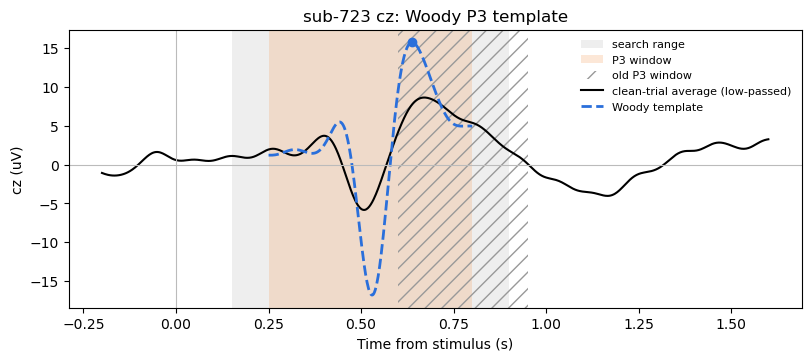

In [3]:
idx = wd['win_idx']
w0, w1 = comp['win']
L = F.WOODY_MAX_LAG
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.axvspan(w0 - L, w1 + L, color='#eeeeee', lw=0, label='search range')
ax.axvspan(w0, w1, color='#f4a261', alpha=0.25, lw=0, label=f'{COMP} window')
ax.axvspan(0.60, 0.95, fill=False, hatch='//', edgecolor='#999999', lw=0, label='old P3 window')
ax.plot(times, Y[df.ok.values].mean(0), color='k', lw=1.5, label='clean-trial average (low-passed)')
ax.plot(times[idx], wd['template'], color='#2a6fdb', lw=2, ls='--', label='Woody template')
ax.plot(times[idx][wd['peak_idx']], wd['template'][wd['peak_idx']], 'o', color='#2a6fdb')
ax.axhline(0, color='#bbbbbb', lw=0.8); ax.axvline(0, color='#bbbbbb', lw=0.8)
ax.set(xlabel='Time from stimulus (s)', ylabel=f'{CH} (uV)', title=f'{SUBJECT} {CH}: Woody {COMP} template')
ax.legend(frameon=False, fontsize=8)
savefig(fig, 'template')
plt.show()

In [4]:
def plot_trials(trials, title, name, ncol=4):
    n = len(trials)
    if n == 0:
        print('no trials to plot'); return
    nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.9 * nrow), sharex=True, constrained_layout=True)
    axs = np.atleast_1d(axs).ravel()
    for ax, (i, r) in zip(axs, trials.iterrows()):
        ax.axvspan(w0 - L, w1 + L, color='#eeeeee', lw=0)
        ax.axvspan(w0, w1, color='#f4a261', alpha=0.25, lw=0)
        ax.plot(times, X[i], color='#bbbbbb', lw=0.7)
        ax.plot(times, Y[i], color='k', lw=1.3)
        ax.plot(times[idx] + r.lag_s, wd['template'], color='#2a6fdb', lw=1.5, ls='--')
        ax.plot([r.n2_lat, r.lat], [r.n2, r.amp], color='#7b2cbf', lw=1, ls=':')
        ax.plot(r.n2_lat, r.n2, 'o', color='#7b2cbf', ms=6, zorder=5)
        ax.plot(r.lat, r.amp, 'o', color='#d1495b', ms=7, zorder=5)
        ax.axhline(0, color='#bbbbbb', lw=0.8); ax.axvline(0, color='#bbbbbb', lw=0.8)
        flags = ('EDGE ' if r.edge else '') + ('' if r.ok else 'REJECTED')
        old_txt = f'old amp {r.amp_old:.1f}, ' if np.isfinite(r.amp_old) else ''
        ax.set_title(f"run {r.run} trial {r.trial_idx}: {old_txt}new amp {r.amp:.1f}\n"
                     f"N2-P3 ptp {r.ptp:.1f} uV, lag {r.lag_s * 1e3:+.0f} ms, r = {r.r_woody:.2f} {flags}", fontsize=8.5)
    for ax in axs[n:]:
        ax.set_visible(False)
    for ax in axs[::ncol]:
        ax.set_ylabel(f'{CH} (uV)')
    for ax in axs[-ncol:]:
        ax.set_xlabel('Time (s)')
    fig.suptitle(title)
    savefig(fig, name)
    plt.show()

## Trials that were negative with the old window, re-scored

saved ./vis_p3_peak_sub-723_cz_previously_negative_trials.png


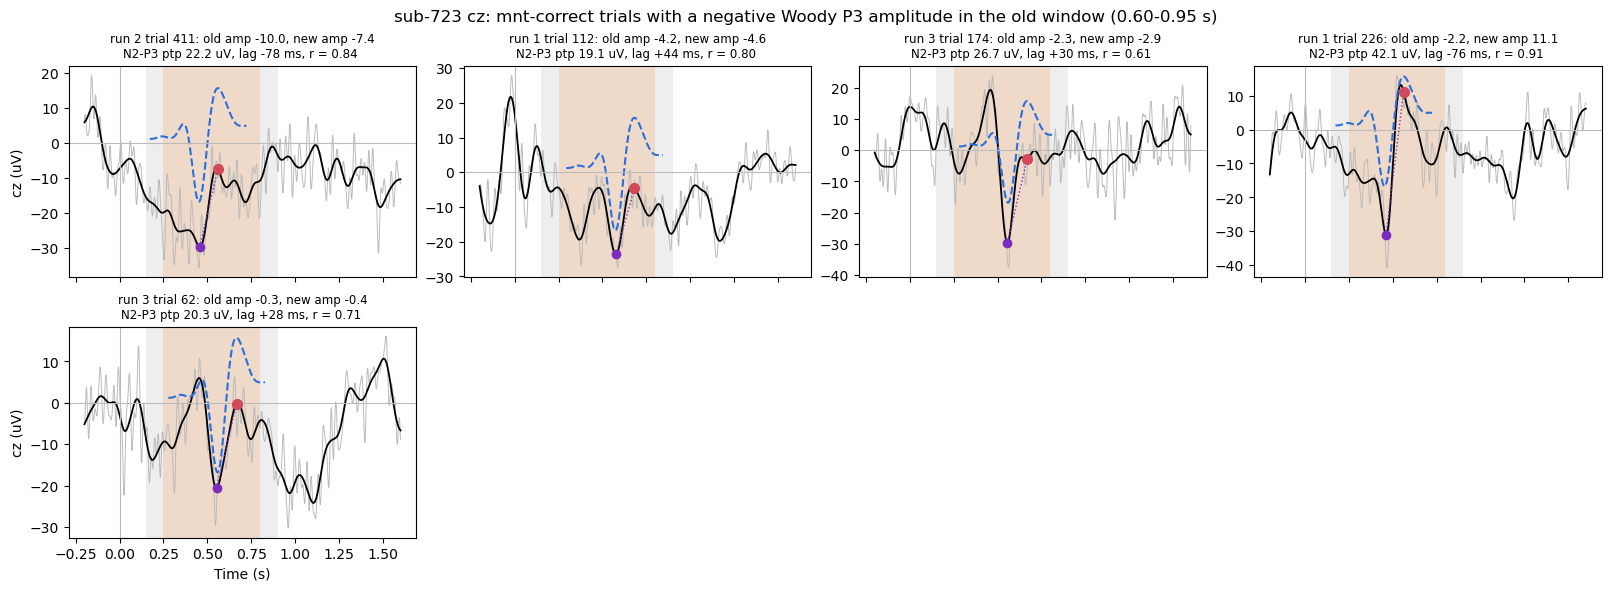

In [5]:
prev_neg = d[d.amp_old < 0].sort_values('amp_old').head(N_EXAMPLES)
plot_trials(prev_neg, f'{SUBJECT} {CH}: {TRIAL_FILTER} trials with a negative Woody {COMP} amplitude in the old window (0.60-0.95 s)',
            'previously_negative_trials')

## Smallest N2-to-P3 peak-to-peak amplitudes

saved ./vis_p3_peak_sub-723_cz_smallest_ptp_trials.png


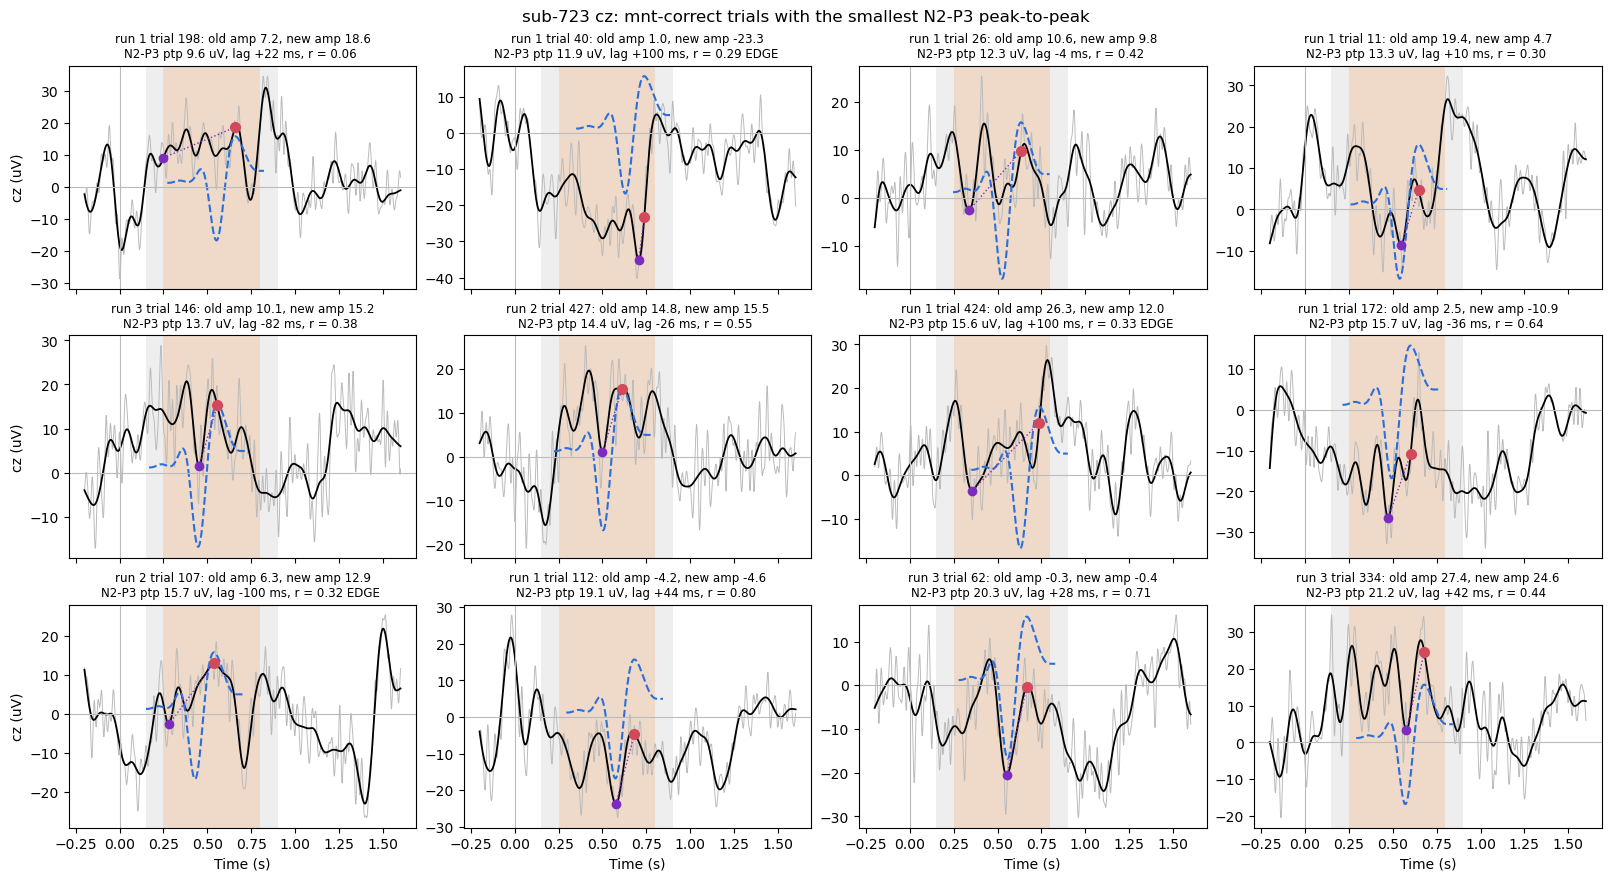

In [6]:
plot_trials(d.sort_values('ptp').head(N_EXAMPLES), f'{SUBJECT} {CH}: {TRIAL_FILTER} trials with the smallest N2-P3 peak-to-peak',
            'smallest_ptp_trials')

## Typical trials
Closest to the median peak-to-peak amplitude among clean trials.

saved ./vis_p3_peak_sub-723_cz_typical_trials.png


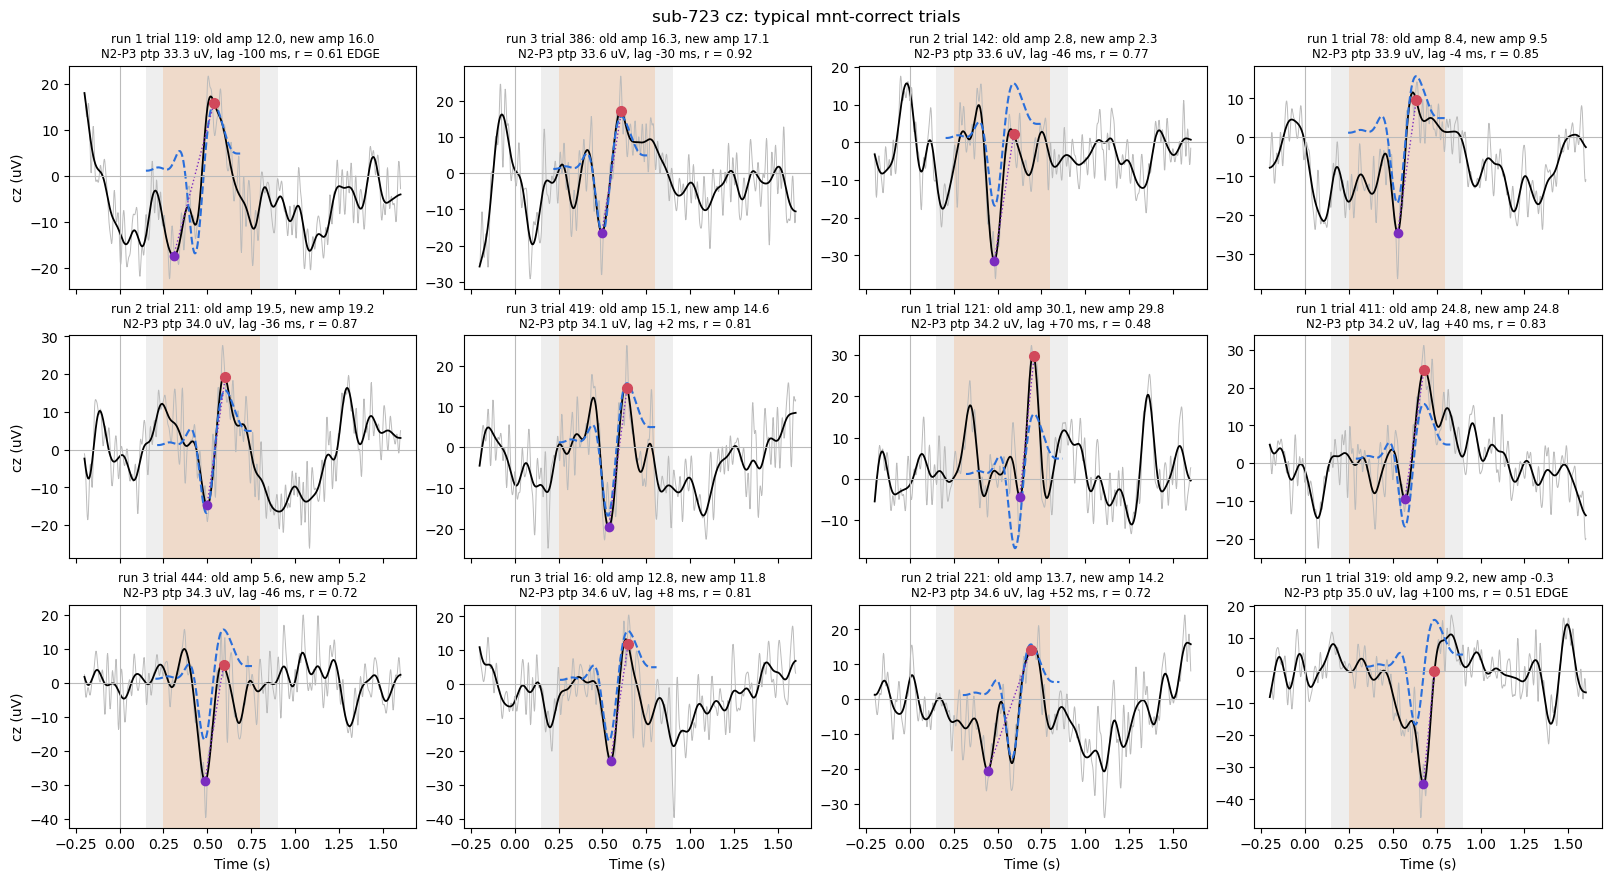

In [7]:
dc = d[d.ok]
typical = dc.iloc[np.argsort(np.abs(dc.ptp - dc.ptp.median()).values)[:N_EXAMPLES]].sort_values('ptp')
plot_trials(typical, f'{SUBJECT} {CH}: typical {TRIAL_FILTER} trials', 'typical_trials')

## Old amplitude, new amplitude and peak-to-peak

saved ./vis_p3_peak_sub-723_cz_old_vs_new.png


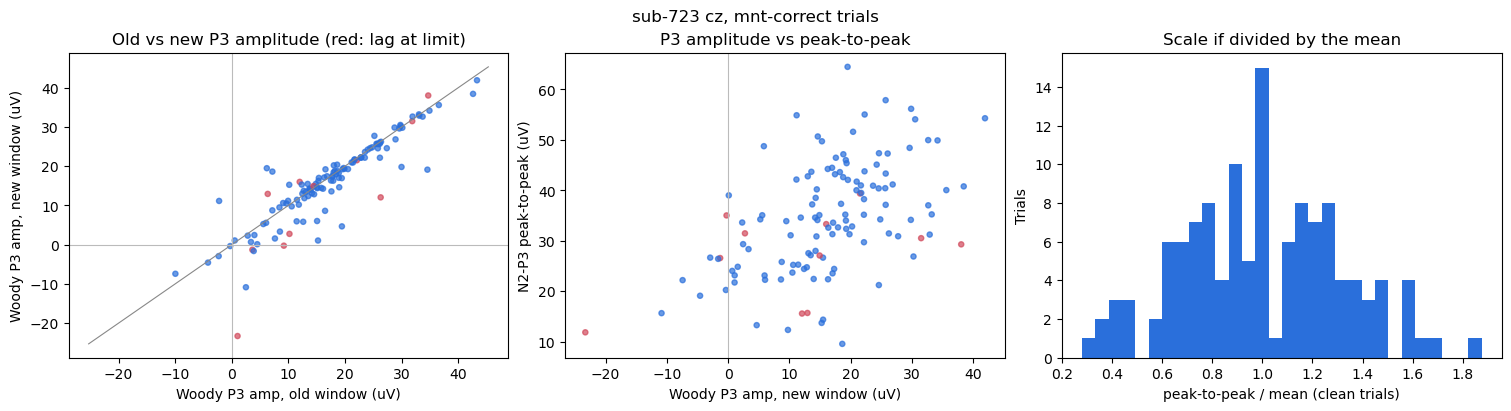

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
lim = [min(d.amp_old.min(), d.amp.min()) - 2, max(d.amp_old.max(), d.amp.max()) + 2]
ax[0].scatter(d.amp_old, d.amp, s=14, c=np.where(d.edge, '#d1495b', '#2a6fdb'), alpha=0.7)
ax[0].plot(lim, lim, color='#888888', lw=0.8); ax[0].axhline(0, color='#bbbbbb', lw=0.8); ax[0].axvline(0, color='#bbbbbb', lw=0.8)
ax[0].set(xlabel='Woody P3 amp, old window (uV)', ylabel='Woody P3 amp, new window (uV)', title='Old vs new P3 amplitude (red: lag at limit)')
ax[1].scatter(d.amp, d.ptp, s=14, c=np.where(d.edge, '#d1495b', '#2a6fdb'), alpha=0.7)
ax[1].axvline(0, color='#bbbbbb', lw=0.8)
ax[1].set(xlabel='Woody P3 amp, new window (uV)', ylabel='N2-P3 peak-to-peak (uV)', title='P3 amplitude vs peak-to-peak')
ax[2].hist(d.ptp / d.ptp[d.ok].mean(), bins=30, color='#2a6fdb')
ax[2].set(xlabel='peak-to-peak / mean (clean trials)', ylabel='Trials', title='Scale if divided by the mean')
fig.suptitle(f'{SUBJECT} {CH}, {TRIAL_FILTER} trials')
savefig(fig, 'old_vs_new')
plt.show()

## Counts for the subjects with a DM
From the saved feature tables, mnt-correct trials on the channel above.

In [9]:
rows = []
for s in DM_SUBJECTS:
    f = F.load_trial_features(s).merge(load_old_features(s)[['run', 'trial_idx', f'{CH}_{COMP}_amp_woody']]
                                       .rename(columns={f'{CH}_{COMP}_amp_woody': 'amp_old'}), on=['run', 'trial_idx'])
    m = (f.trial_type == 'mnt') & (f.response_code == 0)
    ptp = f.loc[m, f'{CH}_N2P3_ptp_woody']
    rows.append(dict(subject=s, trials=int(m.sum()), neg_old_window=int((f.loc[m, 'amp_old'] < 0).sum()),
                     neg_new_window=int((f.loc[m, f'{CH}_{COMP}_amp_woody'] < 0).sum()),
                     edge_new=int(f.loc[m, f'{CH}_{COMP}_edge_woody'].astype(bool).sum()),
                     ptp_min=round(ptp.min(), 1), ptp_median=round(ptp.median(), 1), ptp_zero=int((ptp == 0).sum())))
counts = pd.DataFrame(rows)
counts.to_csv(os.path.join(SAVE_DIR, f'vis_p3_peak_counts_{CH}.csv'), index=False)
counts

,subject,trials,neg_old_window,neg_new_window,edge_new,ptp_min,ptp_median,ptp_zero
0,sub-670,128,2,3,22,7.9,34.2,0
1,sub-695,95,2,3,15,5.6,39.1,0
2,sub-721,108,9,15,28,1.3,19.2,0
3,sub-723,124,5,9,11,9.6,34.1,0
4,sub-726,83,10,12,14,0.0,24.3,1
5,sub-730,94,5,7,19,6.6,35.1,0
